# Características y particiones

Usa EEG/EOG/EMG reales y funciones compartidas del paquete. Las estadísticas exploratorias de features se restringen a desarrollo.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sleep_staging.config import project_root, local_config, experiment_config, data_config

root = project_root()
cfg = experiment_config(root / "configs/experiments/rf-eeg.yaml")
data = data_config(root / cfg.data_config)
settings = local_config()
assert data.source in {"sleep-cassette", "sleep-telemetry"}
print("Dataset real:", data.name, "| Tarea:", cfg.task)


Dataset real: sc-pilot | Tarea: task_5


In [2]:
from sleep_staging.data.preprocess import prepare_dataset, extract_dataset_features
from sleep_staging.experiments import create_splits, experiment_frame
prepared = prepare_dataset(data, cfg, root)
feature_path = extract_dataset_features(prepared, cfg, root)
split_path = create_splits(prepared, cfg, root)
frame, columns = experiment_frame(prepared, feature_path, split_path, cfg)
development = frame[frame.partition.eq("development")]
display(pd.read_parquet(split_path / "subjects.parquet"))
assert frame.groupby("subject_id").fold.nunique().max() == 1
print("Versión:", prepared.name)
print("Features del perfil:", len(columns))
print("Épocas de desarrollo:", len(development))


/Users/adrianalarcon/Documents/uniandes/maia_despliegue_tesis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,subject_id,partition,fold
0,sleep-cassette:00,development,2
1,sleep-cassette:01,test,-1
2,sleep-cassette:02,development,4
3,sleep-cassette:03,development,1
4,sleep-cassette:04,development,2
5,sleep-cassette:05,test,-1
6,sleep-cassette:06,development,0
7,sleep-cassette:07,development,3


Versión: dded564a47dfb085625a
Features del perfil: 25
Épocas de desarrollo: 1440


In [3]:
epochs = pd.read_parquet(prepared / "epochs.parquet")
display(epochs.reason.value_counts().rename("épocas").to_frame())
display(development[cfg.task].value_counts().rename("épocas de desarrollo").to_frame())
display(development[columns].describe().T)


,épocas
reason,
pilot_subsample,20028
,1920


,épocas de desarrollo
task_5,
W,1005
N2,241
REM,88
N3,64
N1,42


,count,mean,std,min,25%,50%,75%,max
eeg_fpz_cz__eeg__mean,1440.0,-0.000985,0.246649,-1.090787,-0.111345,-0.001833,0.100578,1.285560
eeg_fpz_cz__eeg__std,1440.0,20.849679,11.591928,1.100517,12.368099,17.948858,26.203776,70.128730
eeg_fpz_cz__eeg__rms,1440.0,20.850872,11.592405,1.100625,12.369685,17.950268,26.204448,70.128839
eeg_fpz_cz__eeg__q10,1440.0,-23.736445,14.381428,-91.201353,-30.105250,-19.467647,-13.053934,-1.398987
eeg_fpz_cz__eeg__median,1440.0,0.177446,1.003731,-4.906299,-0.253267,0.070577,0.540301,6.566462
eeg_fpz_cz__eeg__q90,1440.0,23.928484,14.189214,1.336308,13.441023,20.167250,29.842573,90.324477
eeg_fpz_cz__eeg__ptp,1440.0,162.116120,78.158458,9.552536,109.147968,146.221249,195.609896,439.596985
eeg_fpz_cz__eeg__skew,1440.0,-0.165630,0.451396,-3.693674,-0.426338,-0.119235,0.108178,2.264304
eeg_fpz_cz__eeg__kurtosis,1440.0,2.478705,2.417772,-0.653996,0.868609,1.882959,3.262644,26.349679
eeg_fpz_cz__eeg__zero_crossings,1440.0,0.112431,0.042200,0.031344,0.082694,0.106369,0.135712,0.302101


## Potencia relativa por estadio en desarrollo

Las transformaciones que aprenden parámetros se ajustan dentro de cada fold, no en este notebook.

,delta,theta,alpha,sigma,beta
task_5,,,,,
N1,0.691942,0.136548,0.077233,0.026344,0.067933
N2,0.789619,0.105777,0.040139,0.049710,0.014755
N3,0.929901,0.045974,0.013127,0.008584,0.002414
REM,0.732214,0.158731,0.058459,0.017519,0.033077
W,0.835829,0.086231,0.024658,0.013760,0.039521


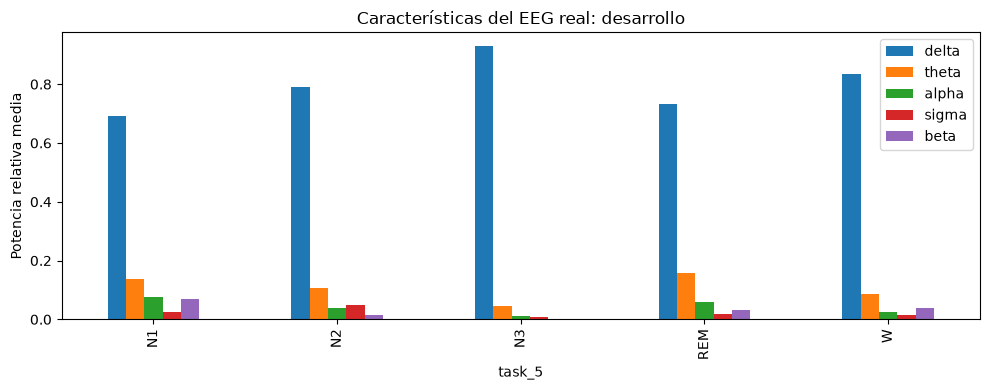

In [4]:
spectral = [f"eeg_fpz_cz__eeg__relative_{band}" for band in ["delta", "theta", "alpha", "sigma", "beta"]]
means = development.groupby(cfg.task)[spectral].mean()
means.columns = ["delta", "theta", "alpha", "sigma", "beta"]
display(means)
means.plot.bar(figsize=(10, 4), ylabel="Potencia relativa media", title="Características del EEG real: desarrollo")
plt.tight_layout()
plt.show()
